In [1]:
# The purpose of this notebook is to add all 25 instance to the 
# simple GP model (only looking at wet strength output for now)

In [2]:
# import the data

from pathlib import Path
import pandas as pd
import numpy as np

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
path = project_root / 'data' / 'clean' / 'train_scaled.csv'

df = pd.read_csv(path)

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]

rng = np.random.RandomState(1)
X = df[formula_cols].fillna(0).to_numpy()
y = df['Wet Strength Mean'].to_numpy()

print(df.head())
print(X)
print(y)

   TEM   Joncryl  NC513  PEG-DE  NGDE  Avg_Density_g_cm3  Avg_Density SE  \
0  0.5       NaN    NaN     NaN   NaN           0.192000        0.002667   
1  0.5 -0.959381    NaN     NaN   NaN           0.195000        0.007263   
2  0.5 -0.520342    NaN     NaN   NaN           0.159000        0.005033   
3  0.5  0.211389    NaN     NaN   NaN           0.159933        0.004410   
4  0.5  0.943121    NaN     NaN   NaN           0.201000        0.008817   

   Dry Strength Mean  Dry Strength SE  Wet Strength Mean  Wet Strength SE  \
0          53.674733         1.008133          23.680000         0.200000   
1          68.863717         4.243165          24.258481         1.187076   
2          50.405845         2.550662          21.329450         1.916881   
3          54.717605         0.566776          20.183592         0.276639   
4          85.787785         6.781653          27.585357         2.274881   

   std_Avg_Density_g_cm3  std_Dry Strength Mean  std_Wet Strength Mean  
0      

In [3]:
# break X and y into LOOCV folds, refit the model on each fold/ print
# evaluation metrics

import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.metrics import r2_score


kernel = RBF(length_scale=1.0, length_scale_bounds=(1e-10, 1e4))

model = GaussianProcessRegressor(
    kernel=kernel, 
    normalize_y=True, 
    n_restarts_optimizer=10,
    alpha=0,
    random_state = 0
)

# LOOCV cross-validation
from sklearn.model_selection import LeaveOneOut
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import r2_score

loo = LeaveOneOut()

val_predictions = []
val_actuals = []
train_r2_scores = []

fold_num = 1
for train_idx, val_idx in loo.split(X):
    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]
    
    # Fit model on training fold
    model.fit(X_train, y_train)
    
    # Store validation prediction
    val_pred = model.predict(X_val)
    val_predictions.append(val_pred[0])
    val_actuals.append(y_val[0])
    
    # Evaluate on training fold
    train_pred = model.predict(X_train)
    train_r2 = r2_score(y_train, train_pred)
    train_r2_scores.append(train_r2)
    
    print(f"Fold {fold_num}: Val Prediction = {val_pred[0]:.3f}, Actual = {y_val[0]:.3f}")
    fold_num += 1

# Calculate R² across ALL out-of-fold predictions
val_r2 = r2_score(val_actuals, val_predictions)

# Calculate averages
avg_train_r2 = np.mean(train_r2_scores)

# Create summary table
results_df = pd.DataFrame({
    'Error Source': ['Goal Performance', 'Train Error', 'Validation Error (LOOCV)', 'Test Error'],
    'Value': [
        'R² = .8',
        f'R² = {avg_train_r2:.3f}',
        f'R² = {val_r2:.3f}',
        ''
    ]
})

print("\n" + "="*50)
print("EVALUATION SUMMARY")
print("="*50)
print(results_df.to_string(index=False))

Fold 1: Val Prediction = 21.805, Actual = 23.680
Fold 2: Val Prediction = 16.746, Actual = 24.258
Fold 3: Val Prediction = 30.201, Actual = 21.329
Fold 4: Val Prediction = 25.197, Actual = 20.184
Fold 5: Val Prediction = 33.723, Actual = 27.585
Fold 6: Val Prediction = 34.043, Actual = 27.922
Fold 7: Val Prediction = 47.809, Actual = 51.134
Fold 8: Val Prediction = 64.490, Actual = 82.812
Fold 9: Val Prediction = 77.628, Actual = 77.134
Fold 10: Val Prediction = 40.484, Actual = 76.406
Fold 11: Val Prediction = 33.774, Actual = 35.350
Fold 12: Val Prediction = 32.804, Actual = 19.560
Fold 13: Val Prediction = 31.611, Actual = 19.610
Fold 14: Val Prediction = 31.155, Actual = 16.730
Fold 15: Val Prediction = 31.850, Actual = 16.970
Fold 16: Val Prediction = 31.768, Actual = 17.040
Fold 17: Val Prediction = 31.304, Actual = 19.620
Fold 18: Val Prediction = 32.263, Actual = 29.008
Fold 19: Val Prediction = 30.451, Actual = 27.360
Fold 20: Val Prediction = 30.673, Actual = 20.682
Fold 21: 

In [4]:
# check the model trained on all of our points predicting the training values

kernel = RBF(length_scale=1.0, length_scale_bounds=(1e-10, 1e4))

model = GaussianProcessRegressor(
    kernel=kernel, 
    normalize_y=True, 
    n_restarts_optimizer=10,
    alpha=0,
    random_state = 0
)

model.fit(X, y)
y_pred = model.predict(X)

comparison_df = pd.DataFrame({
    'Actual': y,
    'Prediction': y_pred
})

print(comparison_df.to_string(index=False))

   Actual  Prediction
23.680000   23.680000
24.258481   24.258481
21.329450   21.329450
20.183592   20.183592
27.585357   27.585357
27.921901   27.921901
51.133703   51.133703
82.812461   82.812461
77.134354   77.134354
76.406460   76.406460
35.349977   35.349977
19.560000   19.560000
19.610000   19.610000
16.730000   16.730000
16.970000   16.970000
17.040000   17.040000
19.620000   19.620000
29.008360   29.008360
27.359952   27.359952
20.681917   20.681917
25.887025   25.887025
28.978707   28.978707
25.604407   25.604407
49.374470   49.374470
60.731681   60.731681


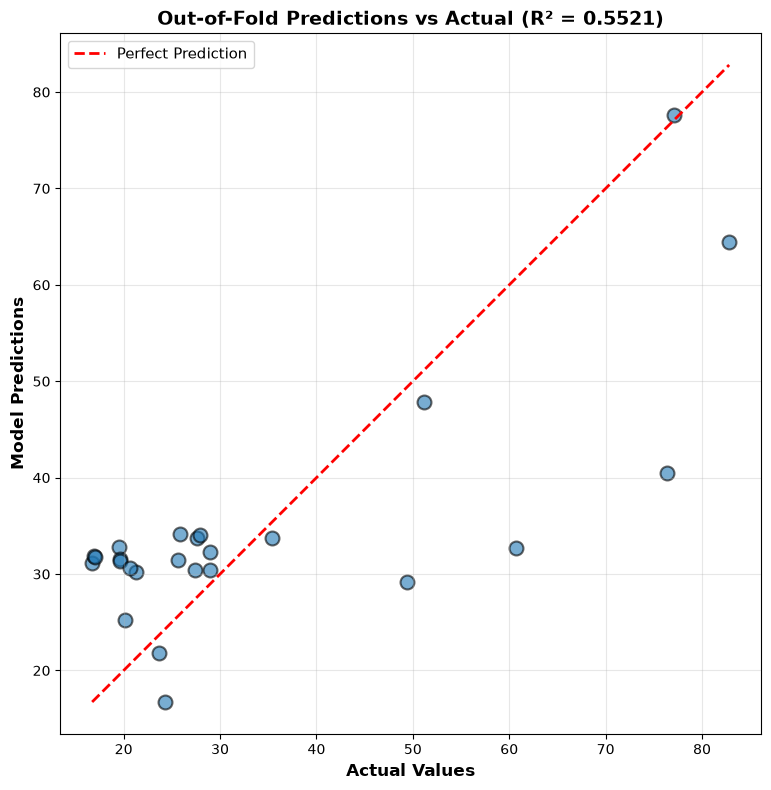

In [5]:
# print out actual vs out of fold prediction and show R^2
import matplotlib.pyplot as plt

# Calculate R²
val_r2 = r2_score(val_actuals, val_predictions)

# Create plot
fig, ax = plt.subplots(figsize=(10, 8))

# Scatter plot
ax.scatter(val_actuals, val_predictions, s=100, alpha=0.6, edgecolors='black', linewidth=1.5)

# Perfect prediction line (y=x)
min_val = min(val_actuals + val_predictions)
max_val = max(val_actuals + val_predictions)
ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')

# Labels and title
ax.set_xlabel('Actual Values', fontsize=12, fontweight='bold')
ax.set_ylabel('Model Predictions', fontsize=12, fontweight='bold')
ax.set_title(f'Out-of-Fold Predictions vs Actual (R² = {val_r2:.4f})', 
             fontsize=14, fontweight='bold')

# Grid and legend
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)

# Equal aspect ratio for better comparison
ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()

In [6]:
# Create dataframe with predictions vs actuals
comparison_df = pd.DataFrame({
    'Actual': val_actuals,
    'Prediction': val_predictions,
    'Residual': np.array(val_actuals) - np.array(val_predictions),
    'Abs_Error': np.abs(np.array(val_actuals) - np.array(val_predictions))
})

# Calculate R²
val_r2 = r2_score(val_actuals, val_predictions)

print("\n" + "="*70)
print("OUT-OF-FOLD VALIDATION PREDICTIONS")
print("="*70)
print(comparison_df.to_string(index=False))
print("="*70)
print(f"R² Score: {val_r2:.4f}")
print(f"Mean Absolute Error: {comparison_df['Abs_Error'].mean():.4f}")
print(f"RMSE: {np.sqrt(np.mean(comparison_df['Residual']**2)):.4f}")
print("="*70)


OUT-OF-FOLD VALIDATION PREDICTIONS
   Actual  Prediction   Residual  Abs_Error
23.680000   21.804728   1.875272   1.875272
24.258481   16.746096   7.512385   7.512385
21.329450   30.201175  -8.871725   8.871725
20.183592   25.197260  -5.013668   5.013668
27.585357   33.722736  -6.137378   6.137378
27.921901   34.042930  -6.121029   6.121029
51.133703   47.808593   3.325110   3.325110
82.812461   64.489774  18.322687  18.322687
77.134354   77.627995  -0.493641   0.493641
76.406460   40.484367  35.922093  35.922093
35.349977   33.774160   1.575817   1.575817
19.560000   32.804486 -13.244486  13.244486
19.610000   31.611196 -12.001196  12.001196
16.730000   31.155284 -14.425284  14.425284
16.970000   31.850091 -14.880091  14.880091
17.040000   31.768086 -14.728086  14.728086
19.620000   31.304347 -11.684347  11.684347
29.008360   32.262565  -3.254205   3.254205
27.359952   30.451023  -3.091071   3.091071
20.681917   30.673139  -9.991222   9.991222
25.887025   34.127712  -8.240687   8.240

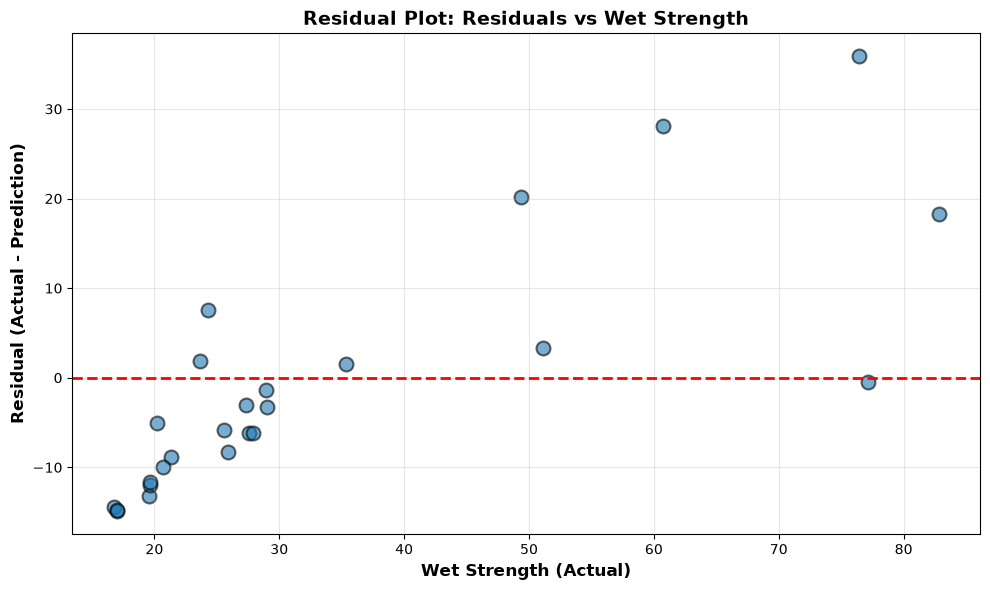

In [7]:
plt.figure(figsize=(10, 6))
plt.scatter(comparison_df['Actual'], comparison_df['Residual'], s=100, alpha=0.6, edgecolors='black', linewidth=1.5)
plt.axhline(y=0, color='r', linestyle='--', linewidth=2)
plt.xlabel('Wet Strength (Actual)', fontsize=12, fontweight='bold')
plt.ylabel('Residual (Actual - Prediction)', fontsize=12, fontweight='bold')
plt.title('Residual Plot: Residuals vs Wet Strength', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()